# Point-supervised segmentation on LoveDA with partial focal CE

Train a land-cover segmentation model when only a few pixels per image are labeled.

1. Partial (focal) cross-entropy loss
2. LoveDA + simulated point labels sampled from the full masks, U-Net (ResNet-34) trained with the loss
3. Experiments: number of points per image, and the focal gamma



## 0. Setup

In [2]:
import os, json, math, time, random, hashlib, zipfile, urllib.request
from contextlib import nullcontext
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import segmentation_models_pytorch as smp
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

DATA_ROOT = Path("data/LoveDA")   # where downloaded/uploaded zips get extracted
SEARCH_DIRS = [Path("data")]       # where the zips (or an extracted copy) are looked for
OUT = Path("outputs")             # runs, point labels, figures
(OUT / "figures").mkdir(parents=True, exist_ok=True)

CFG = dict(
    arch="Unet", encoder="resnet34", weights="imagenet",
    iters=8000, batch_size=8, crop=512,
    lr=3e-4, wd=1e-4, warmup=300,
    eval_every=2000, eval_bs=2,
    num_workers=6,          # i9-12900H; set to 0 if the DataLoader hangs on Windows
    amp=True,               # mixed precision: bf16 if the GPU supports it, else fp16
)

CLASSES = ["background", "building", "road", "water", "barren", "forest", "agriculture"]
NUM_CLASSES = len(CLASSES)
IGNORE = 255

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = CFG["amp"] and device.type == "cuda"
# bf16 is only fast on Ampere or newer (compute capability >= 8); a T4 (7.5) emulates it, so use fp16 there
native_bf16 = device.type == "cuda" and torch.cuda.get_device_capability()[0] >= 8
amp_dtype = torch.bfloat16 if native_bf16 else torch.float16
if device.type == "cuda":
    torch.backends.cudnn.benchmark = True
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    print(torch.cuda.get_device_name(0), f"{torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
print("torch", torch.__version__, "| smp", smp.__version__, "| device", device,
      "| amp", str(amp_dtype).replace("torch.", "") if use_amp else "off")


def amp_ctx():
    return torch.autocast("cuda", dtype=amp_dtype) if use_amp else nullcontext()


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

NVIDIA RTX A2000 8GB Laptop GPU 8.6 GB
torch 2.6.0+cu124 | smp 0.5.0 | device cuda | amp bfloat16


## 1. Data



In [3]:
ZENODO = {
    "Train.zip": "de2b196043ed9b4af1690b3f9a7d558f",
    "Val.zip":   "84cae2577468ff0b5386758bb386d31d",
}
ZENODO_URLS = [
    "https://zenodo.org/records/5706578/files/{}?download=1",
    "https://zenodo.org/api/records/5706578/files/{}/content",
    "https://zenodo.org/record/5706578/files/{}",
]
HEADERS = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) "
                         "Chrome/126.0 Safari/537.36", "Accept": "*/*"}


def md5(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()


def find_loveda(bases, max_depth=6):
    # returns {("train"|"val", "urban"|"rural"): scene_dir} for any folder layout like .../Train/Urban/images_png
    found = {}
    for base in bases:
        if not base.exists():
            continue
        for depth in range(2, max_depth + 1):
            for img_dir in base.glob("*/" * depth + "images_png"):
                scene, split = img_dir.parent.name.lower(), img_dir.parent.parent.name.lower()
                if scene in ("urban", "rural") and split in ("train", "val") and (img_dir.parent / "masks_png").is_dir():
                    found.setdefault((split, scene), img_dir.parent)
            if len(found) == 4:
                return found
    return found


def find_zip(name, bases, max_depth=3):
    for base in bases:
        if not base.exists():
            continue
        for depth in range(0, max_depth + 1):
            for p in base.glob("*/" * depth + name):
                return p
    return None


def download(name, dest):
    for url in ZENODO_URLS:
        url = url.format(name)
        try:
            req = urllib.request.Request(url, headers=HEADERS)
            with urllib.request.urlopen(req, timeout=60) as r, open(dest.with_suffix(".part"), "wb") as f:
                total = int(r.headers.get("Content-Length", 0)) or None
                with tqdm(total=total, unit="B", unit_scale=True, desc=name) as bar:
                    for b in iter(lambda: r.read(1 << 20), b""):
                        f.write(b)
                        bar.update(len(b))
            dest.with_suffix(".part").replace(dest)
            return True
        except Exception as e:
            print(f"  {url} -> {e}")
    return False


LOVEDA = find_loveda(SEARCH_DIRS)
if len(LOVEDA) < 4:
    DATA_ROOT.mkdir(parents=True, exist_ok=True)
    for name, checksum in ZENODO.items():
        split = name.replace(".zip", "").lower()
        if (split, "urban") in LOVEDA and (split, "rural") in LOVEDA:
            continue
        zpath = find_zip(name, SEARCH_DIRS)
        if zpath is None:
            zpath = DATA_ROOT / name
            print(f"{name} not found locally, trying Zenodo")
            if not download(name, zpath):
                raise RuntimeError(
                    f"Could not download {name}. Download Train.zip and Val.zip in your browser from "
                    f"https://zenodo.org/records/5706578 and put them in {DATA_ROOT.resolve()} "
                    f"then re-run this cell.")
        print(f"checking {zpath}")
        assert md5(zpath) == checksum, f"{zpath} has the wrong MD5 (incomplete download?). Delete it and retry."
        with zipfile.ZipFile(zpath) as z:
            z.extractall(DATA_ROOT)
    LOVEDA = find_loveda(SEARCH_DIRS)

assert len(LOVEDA) == 4, f"LoveDA folders not found, got {sorted(LOVEDA)}"
EXPECTED = {("train", "urban"): 1156, ("train", "rural"): 1366, ("val", "urban"): 677, ("val", "rural"): 992}
for key, d in sorted(LOVEDA.items()):
    n = len(list((d / "images_png").glob("*.png")))
    flag = "" if n == EXPECTED[key] else f"  <-- expected {EXPECTED[key]}"
    print(f"{key[0]:5s} {key[1]:5s} {n:5d} images  {d}{flag}")

train rural  1366 images  data\LoveDA\Train\Rural
train urban  1156 images  data\LoveDA\Train\Urban
val   rural   992 images  data\LoveDA\Val\Rural
val   urban   677 images  data\LoveDA\Val\Urban


Splits: official Train → 90% train / 10% val (stratified by urban/rural), official Val → test.

Raw mask values: 0 = no-data, 1..7 = classes. No-data becomes 255 (ignored everywhere) and the classes become 0..6.

In [4]:
def scan(official_split):
    recs = []
    for scene in ["Urban", "Rural"]:
        scene_dir = LOVEDA[(official_split.lower(), scene.lower())]
        for p in sorted((scene_dir / "images_png").glob("*.png")):
            m = scene_dir / "masks_png" / p.name
            assert m.exists(), m
            recs.append(dict(id=f"{scene}_{p.stem}", scene=scene, image=str(p), mask=str(m)))
    return recs

def train_val_split(recs, val_frac=0.1, seed=0):
    rng = np.random.default_rng(seed)
    train, val = [], []
    for scene in ["Urban", "Rural"]:
        group = [r for r in recs if r["scene"] == scene]
        perm = rng.permutation(len(group))
        k = round(len(group) * val_frac)
        val += [group[i] for i in perm[:k]]
        train += [group[i] for i in perm[k:]]
    return sorted(train, key=lambda r: r["id"]), sorted(val, key=lambda r: r["id"])

train_recs, val_recs = train_val_split(scan("Train"))
splits = {"train": train_recs, "val": val_recs, "test": scan("Val")}
json.dump(splits, open(OUT / "splits.json", "w"), indent=1)
for k, v in splits.items():
    print(f"{k:5s} {len(v):5d}  (urban {sum(r['scene'] == 'Urban' for r in v)}, rural {sum(r['scene'] == 'Rural' for r in v)})")

train  2269  (urban 1040, rural 1229)
val     253  (urban 116, rural 137)
test   1669  (urban 677, rural 992)


The dataset code goes in a small `.py` file so DataLoader worker processes can import it (on Windows they can't see classes defined inside a notebook).

Training uses random 512 crops at native resolution plus flips/90° rotations. All of these are exact pixel operations, so sparse point labels never get resized or shifted. Evaluation uses full 1024×1024 images.

In [5]:
%%writefile loveda_ds.py
import cv2
import numpy as np
import torch
from torch.utils.data import Dataset

IGNORE = 255
LUT = np.full(256, IGNORE, np.uint8)
LUT[1:8] = np.arange(7)          # raw 0 (no-data) -> 255, raw 1..7 -> 0..6


def read_img(path):
    img = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if img is None:
        raise FileNotFoundError(path)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def read_mask(path):
    m = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    if m is None:
        raise FileNotFoundError(path)
    if m.ndim == 3:
        m = m[..., 0]
    return LUT[m]


def points_to_label(pts, shape):
    lab = np.full(shape, IGNORE, np.uint8)
    if len(pts):
        lab[pts[:, 0], pts[:, 1]] = pts[:, 2]
    return lab


class LoveDA(Dataset):
    # train=True: random crop + flips + rot90, target = point labels (or dense mask if points is None)
    # train=False: full image + dense mask
    def __init__(self, records, points=None, train=True, crop=512):
        self.records, self.points, self.train, self.crop = records, points, train, crop

    def __len__(self):
        return len(self.records)

    def __getitem__(self, i):
        r = self.records[i]
        img = read_img(r["image"])
        if self.points is not None:
            tgt = points_to_label(self.points[r["id"]], img.shape[:2])
        else:
            tgt = read_mask(r["mask"])
        if self.train:
            img, tgt = self.augment(img, tgt)
        img = torch.from_numpy(np.ascontiguousarray(img.transpose(2, 0, 1)))   # uint8, normalized on GPU
        tgt = torch.from_numpy(np.ascontiguousarray(tgt)).long()
        return img, tgt, i

    def augment(self, img, tgt):
        h, w = tgt.shape
        c = self.crop
        if h > c or w > c:
            y, x = np.random.randint(0, h - c + 1), np.random.randint(0, w - c + 1)
            img, tgt = img[y:y + c, x:x + c], tgt[y:y + c, x:x + c]
        if np.random.rand() < 0.5:
            img, tgt = img[:, ::-1], tgt[:, ::-1]
        if np.random.rand() < 0.5:
            img, tgt = img[::-1], tgt[::-1]
        k = np.random.randint(4)
        if k:
            img, tgt = np.rot90(img, k), np.rot90(tgt, k)
        return img, tgt


def worker_init(_):
    np.random.seed(torch.initial_seed() % 2**32)
    cv2.setNumThreads(0)

Overwriting loveda_ds.py


In [6]:
import importlib, loveda_ds
importlib.reload(loveda_ds)
from loveda_ds import LoveDA, read_img, read_mask, points_to_label, worker_init

PALETTE = np.array([[255, 255, 255], [255, 0, 0], [255, 255, 0], [0, 0, 255],
                    [159, 129, 183], [0, 255, 0], [255, 195, 128]], np.uint8)   # official LoveDA colors

def colorize(lab):
    out = np.zeros((*lab.shape, 3), np.uint8)
    v = lab != IGNORE
    out[v] = PALETTE[lab[v]]
    return out

Class balance per split (one pass over all masks, takes a minute or two).

  0%|          | 0/2269 [00:00<?, ?it/s]

  0%|          | 0/253 [00:00<?, ?it/s]

  0%|          | 0/1669 [00:00<?, ?it/s]

,train,val,test
background,35.65,36.99,36.10
building,11.02,11.47,7.21
road,5.26,5.40,4.67
water,6.36,6.69,11.71
barren,5.33,4.20,4.36
forest,16.25,14.49,7.37
agriculture,20.13,20.78,28.58
no-data (% of all px),3.81,3.42,2.62


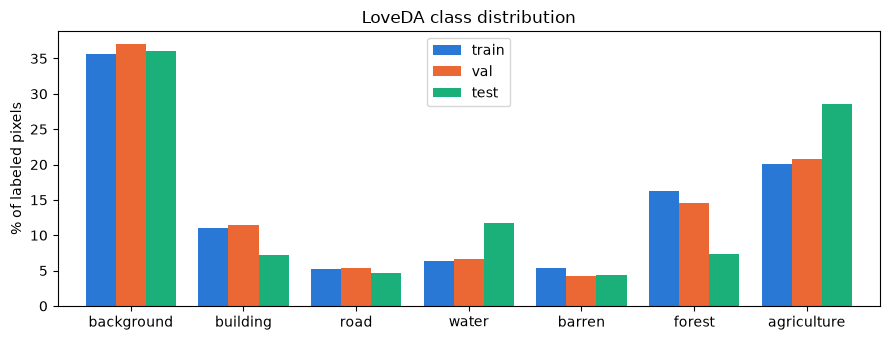

In [7]:
def class_counts(recs):
    def count(r):
        return np.bincount(read_mask(r["mask"]).ravel(), minlength=256)
    total = np.zeros(256, np.int64)
    with ThreadPoolExecutor(8) as ex:
        for c in tqdm(ex.map(count, recs), total=len(recs), leave=False):
            total += c
    return total[:NUM_CLASSES], total[IGNORE]

stats = {}
for k, recs in splits.items():
    cls, nodata = class_counts(recs)
    stats[k] = dict(frac=cls / cls.sum(), nodata=nodata / (cls.sum() + nodata), valid_px=int(cls.sum()))

dist = pd.DataFrame({k: v["frac"] * 100 for k, v in stats.items()}, index=CLASSES).round(2)
dist.loc["no-data (% of all px)"] = [round(v["nodata"] * 100, 2) for v in stats.values()]
display(dist)

ax = dist.iloc[:NUM_CLASSES].plot.bar(figsize=(9, 3.5), width=0.8, color=["#2a78d6", "#eb6834", "#1baf7a"])
ax.set_ylabel("% of labeled pixels")
ax.set_title("LoveDA class distribution")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(OUT / "figures" / "class_distribution.png", dpi=150)
plt.show()

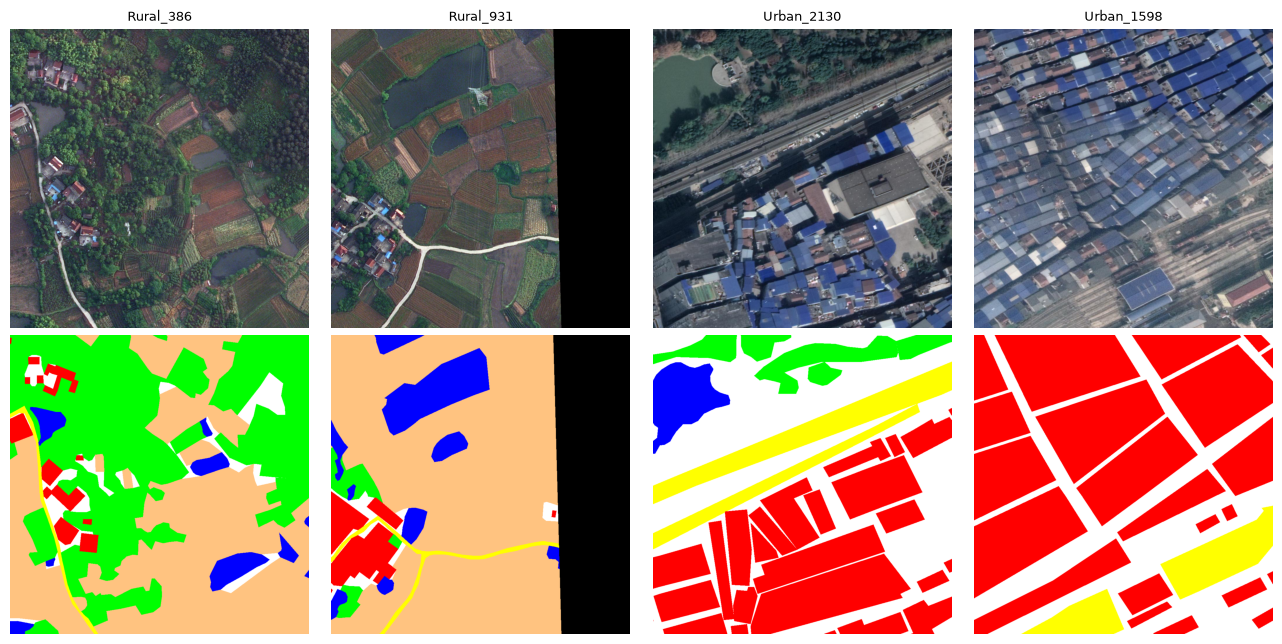

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(13, 6.5))
for j, r in enumerate(np.random.default_rng(0).choice(splits["train"], 4, replace=False)):
    axes[0, j].imshow(read_img(r["image"])); axes[0, j].set_title(r["id"], fontsize=9)
    axes[1, j].imshow(colorize(read_mask(r["mask"])))
for a in axes.ravel():
    a.axis("off")
plt.tight_layout()
plt.show()

## 2. Partial focal cross-entropy



In [9]:
class PartialFocalCE(nn.Module):
    def __init__(self, gamma=0.0, ignore_index=IGNORE):
        super().__init__()
        self.gamma, self.ignore_index = float(gamma), ignore_index

    def forward(self, logits, target):
        labeled = target != self.ignore_index
        n = labeled.sum()
        if n == 0:
            return logits.sum() * 0.0          # no points in this batch -> zero loss, zero grads
        log_p = F.log_softmax(logits.float(), dim=1)
        t = torch.where(labeled, target, torch.zeros_like(target))
        log_pt = log_p.gather(1, t.unsqueeze(1)).squeeze(1)[labeled]
        loss = -log_pt
        if self.gamma > 0:
            loss = (1 - log_pt.exp()).clamp_min(0).pow(self.gamma) * loss
        return loss.sum() / n

Quick sanity checks on the loss.

In [10]:
torch.manual_seed(0)
logits = torch.randn(2, NUM_CLASSES, 16, 16, requires_grad=True)
target = torch.full((2, 16, 16), IGNORE)
idx = torch.randperm(2 * 16 * 16)[:12]
target.view(-1)[idx] = torch.randint(0, NUM_CLASSES, (12,))

# gamma=0 must match PyTorch's CE with ignore_index
assert torch.allclose(PartialFocalCE(0)(logits, target), F.cross_entropy(logits, target, ignore_index=IGNORE), atol=1e-6)

# gamma=2 vs the formula written out with a dense mask
p = F.softmax(logits, 1)
pt = p.gather(1, target.clamp(max=NUM_CLASSES - 1).unsqueeze(1)).squeeze(1)
M = (target != IGNORE).float()
manual = ((-(1 - pt) ** 2 * pt.log()) * M).sum() / M.sum()
assert torch.allclose(PartialFocalCE(2)(logits, target), manual, atol=1e-6)

# unlabeled pixels get exactly zero gradient, labeled ones don't
PartialFocalCE(2)(logits, target).backward()
unl = (target == IGNORE).unsqueeze(1).expand_as(logits)
assert logits.grad[unl].abs().max() == 0 and logits.grad[~unl].abs().sum() > 0

# empty batch: zero loss, finite grads
x = torch.randn(1, NUM_CLASSES, 8, 8, requires_grad=True)
l = PartialFocalCE(0.5)(x, torch.full((1, 8, 8), IGNORE)); l.backward()
assert l.item() == 0 and torch.isfinite(x.grad).all()
print("loss checks passed")

loss checks passed


## 3. Simulated point labels

For each training image, `n` pixels are drawn uniformly at random from the valid (non no-data) pixels and keep their label; everything else is 255. This is like an annotator clicking random spots, so rare classes are often missed.

Points are sampled **once** per (n, seed), on the full 1024×1024 mask, and cached to disk. Every run with that setting sees exactly the same labels. They are not re-drawn every epoch, since that would leak far more labeled pixels than the budget says. The RNG for each image is seeded from (seed, image id), so labels don't depend on processing order.

In [11]:
def sample_points(mask, n, rng):
    flat = mask.ravel()
    valid = np.flatnonzero(flat != IGNORE)
    if len(valid) == 0:
        return np.zeros((0, 3), np.int32)
    idx = np.sort(rng.choice(valid, size=min(n, len(valid)), replace=False))
    r, c = np.divmod(idx, mask.shape[1])
    return np.stack([r, c, flat[idx]], 1).astype(np.int32)   # (k, 3): row, col, class


def image_rng(seed, img_id):
    return np.random.default_rng([seed, int(hashlib.md5(img_id.encode()).hexdigest()[:8], 16)])


def get_points(records, n, seed, cache_dir=OUT / "points"):
    f = Path(cache_dir) / f"uniform_n{n}_s{seed}.npz"
    if f.exists():
        with np.load(f) as z:
            pts = {k: z[k] for k in z.files}
        if all(r["id"] in pts for r in records):
            return pts, json.load(open(f.with_suffix(".json")))
    pts, valid_px = {}, 0
    for r in tqdm(records, desc=f"sampling n={n} seed={seed}", leave=False):
        m = read_mask(r["mask"])
        valid_px += int((m != IGNORE).sum())
        pts[r["id"]] = sample_points(m, n, image_rng(seed, r["id"]))
    per_class = np.bincount(np.concatenate([p[:, 2] for p in pts.values()]), minlength=NUM_CLASSES)
    info = dict(n=n, seed=seed, points=int(per_class.sum()), labeled_frac=per_class.sum() / valid_px,
                per_class=per_class.tolist())
    f.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(f, **pts)
    json.dump(info, open(f.with_suffix(".json"), "w"))
    return pts, info

In [12]:
POINT_BUDGETS = [5, 20, 100, 500]
point_sets = {n: get_points(splits["train"], n, seed=0) for n in POINT_BUDGETS}

pd.DataFrame({f"n={n}": {"labeled px (%)": f"{info['labeled_frac'] * 100:.4f}",
                        **dict(zip(CLASSES, info["per_class"]))}
              for n, (_, info) in point_sets.items()})

,n=5,n=20,n=100,n=500
labeled px (%),0.0005,0.0020,0.0099,0.0496
background,4015,16252,80643,403509
building,1297,4976,25047,125229
road,588,2362,11984,60364
water,721,2900,14665,72988
barren,636,2514,12309,60941
forest,1834,7268,36708,184235
agriculture,2254,9108,45544,227234


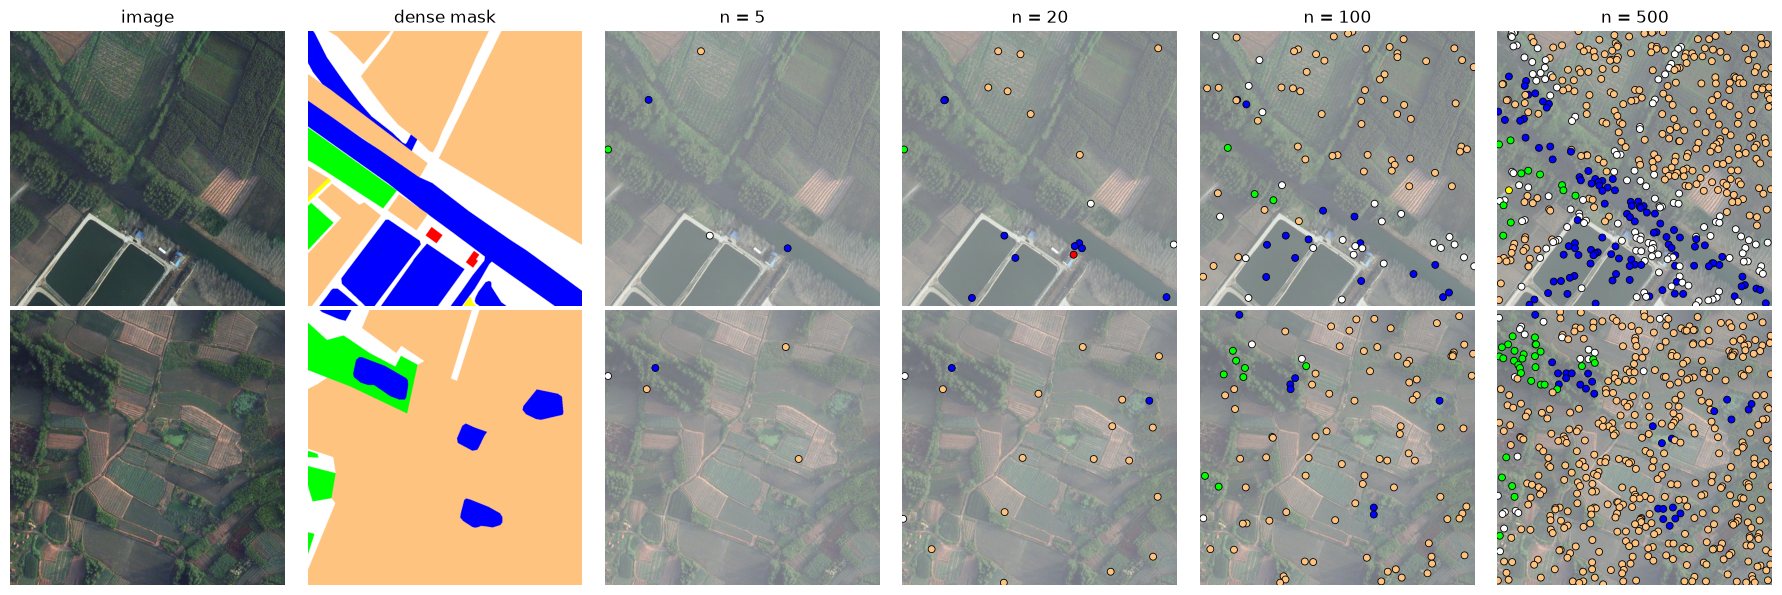

In [13]:
fig, axes = plt.subplots(2, 2 + len(POINT_BUDGETS), figsize=(18, 6))
for row, r in enumerate(splits["train"][:2]):
    img = read_img(r["image"])
    axes[row, 0].imshow(img)
    axes[row, 1].imshow(colorize(read_mask(r["mask"])))
    for j, n in enumerate(POINT_BUDGETS):
        p = point_sets[n][0][r["id"]]
        ax = axes[row, 2 + j]
        ax.imshow(img, alpha=0.6)
        ax.scatter(p[:, 1], p[:, 0], c=PALETTE[p[:, 2]] / 255, s=25, edgecolors="k", linewidths=0.6)
        if row == 0:
            ax.set_title(f"n = {n}")
axes[0, 0].set_title("image"); axes[0, 1].set_title("dense mask")
for a in axes.ravel():
    a.axis("off")
plt.tight_layout()
plt.savefig(OUT / "figures" / "points_examples.png", dpi=120)
plt.show()

## 4. Model, training, evaluation

- U-Net with an ImageNet-pretrained ResNet-34 encoder (segmentation-models-pytorch)
- AdamW, lr 3e-4, wd 1e-4, 300 warm-up iterations then cosine decay
- Same fixed budget for every run: 8000 iterations × batch 8 (512 crops), bf16 autocast
- The **final** checkpoint is evaluated. Dense val mIoU is only logged for monitoring, since with real point labels there would be no dense masks to pick checkpoints with.
- Metrics come from a confusion matrix accumulated over the whole test set (not averaged per image). No-data pixels are excluded.

In [14]:
MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

def to_input(img_uint8):
    x = (img_uint8.to(device, non_blocking=True).float() / 255 - MEAN) / STD
    return x.contiguous(memory_format=torch.channels_last)


def build_model(cfg, weights="default"):
    arch = {"Unet": smp.Unet, "DeepLabV3Plus": smp.DeepLabV3Plus, "FPN": smp.FPN}[cfg["arch"]]
    w = cfg["weights"] if weights == "default" else weights
    return arch(encoder_name=cfg["encoder"], encoder_weights=w, classes=NUM_CLASSES)


def make_loader(ds, bs, train, cfg, seed=0):
    g = torch.Generator()
    g.manual_seed(seed)
    nw = cfg["num_workers"]
    return DataLoader(ds, batch_size=bs, shuffle=train, drop_last=train and len(ds) >= bs,
                      num_workers=nw, persistent_workers=nw > 0, pin_memory=device.type == "cuda",
                      worker_init_fn=worker_init, generator=g)


def scores(cm):
    cm = cm.astype(np.float64)
    if cm.sum() == 0:
        return None
    tp = np.diag(cm)
    with np.errstate(divide="ignore", invalid="ignore"):
        iou = tp / (cm.sum(0) + cm.sum(1) - tp)
    return dict(mIoU=float(np.nanmean(iou)), OA=float(tp.sum() / cm.sum()),
                IoU=dict(zip(CLASSES, iou.tolist())))


@torch.no_grad()
def evaluate(model, records, cfg, tta=False):
    model.eval()
    loader = make_loader(LoveDA(records, train=False), cfg["eval_bs"], False, cfg)
    cms = {k: torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.long, device=device) for k in ["all", "Urban", "Rural"]}
    for img, tgt, idx in tqdm(loader, desc="eval", leave=False):
        x = to_input(img)
        with amp_ctx():
            logits = model(x).float()
            if tta:   # flip TTA, not used for the reported numbers
                logits += model(x.flip(3)).float().flip(3) + model(x.flip(2)).float().flip(2)
        pred, tgt = logits.argmax(1), tgt.to(device)
        for b in range(len(idx)):
            v = tgt[b] != IGNORE
            cm = torch.bincount(tgt[b][v] * NUM_CLASSES + pred[b][v], minlength=NUM_CLASSES ** 2)
            cm = cm.view(NUM_CLASSES, NUM_CLASSES)
            cms["all"] += cm
            cms[records[int(idx[b])]["scene"]] += cm
    out = {k: scores(v.cpu().numpy()) for k, v in cms.items()}
    out["confusion"] = cms["all"].cpu().tolist()
    return out

In [15]:
def run_name(n, gamma, seed):
    return ("dense" if n is None else f"n{n}") + f"_g{gamma:g}_s{seed}"


def train_run(n, gamma, seed, cfg=CFG, out=OUT, recs=splits):
    # n=None -> train on the full masks (upper bound)
    name = run_name(n, gamma, seed)
    rdir = Path(out) / "runs" / name
    if (rdir / "metrics.json").exists():
        print(f"{name}: done already, skipping")
        return json.load(open(rdir / "metrics.json"))
    rdir.mkdir(parents=True, exist_ok=True)
    seed_everything(seed)

    if n is None:
        points, labeled_frac = None, 1.0
    else:
        points, info = get_points(recs["train"], n, seed, Path(out) / "points")
        labeled_frac = info["labeled_frac"]

    loader = make_loader(LoveDA(recs["train"], points, train=True, crop=cfg["crop"]),
                         cfg["batch_size"], True, cfg, seed)
    model = build_model(cfg).to(device, memory_format=torch.channels_last)
    criterion = PartialFocalCE(gamma)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["wd"])
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp and amp_dtype == torch.float16)   # only needed for fp16

    def lr_factor(it):
        if it < cfg["warmup"]:
            return (it + 1) / cfg["warmup"]
        t = min(1.0, (it - cfg["warmup"]) / max(1, cfg["iters"] - cfg["warmup"]))
        return 0.5 * (1 + math.cos(math.pi * t))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_factor)

    # resume if this run was interrupted
    start, ckpt = 0, rdir / "last.pt"
    if ckpt.exists():
        state = torch.load(ckpt, map_location=device, weights_only=False)
        model.load_state_dict(state["model"]); opt.load_state_dict(state["opt"]); sched.load_state_dict(state["sched"])
        start = state["iter"]
        print(f"{name}: resuming from iter {start}")
    log = open(rdir / "log.csv", "a" if start > 0 else "w")
    if start == 0:
        log.write("iter,loss,lr,val_mIoU\n")

    def forever():
        while True:
            yield from loader
    batches = forever()

    model.train()
    running, k, t0 = 0.0, 0, time.time()
    pbar = tqdm(range(start, cfg["iters"]), desc=name, initial=start, total=cfg["iters"])
    for it in pbar:
        img, tgt, _ = next(batches)
        with amp_ctx():
            logits = model(to_input(img))
        loss = criterion(logits, tgt.to(device, non_blocking=True))
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(opt)
        scaler.update()
        sched.step()
        running += loss.detach()
        k += 1

        step = it + 1
        if step % 50 == 0 or step == cfg["iters"]:
            avg = (running / k).item()
            if not math.isfinite(avg):
                raise RuntimeError(f"loss is {avg} at iter {step}")
            pbar.set_postfix(loss=f"{avg:.4f}")
            val_miou = ""
            if step % cfg["eval_every"] == 0 or step == cfg["iters"]:
                val_miou = f"{evaluate(model, recs['val'], cfg)['all']['mIoU']:.4f}"
                torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(), iter=step), ckpt)
                model.train()
            log.write(f"{step},{avg:.5f},{sched.get_last_lr()[0]:.3e},{val_miou}\n")
            log.flush()
            running, k = 0.0, 0
    log.close()
    train_min = (time.time() - t0) / 60

    torch.save(model.state_dict(), rdir / "model.pt")
    test = evaluate(model, recs["test"], cfg)
    metrics = dict(name=name, n=n, gamma=gamma, seed=seed, labeled_frac=labeled_frac,
                   train_min=round(train_min, 1), cfg=cfg, test=test)
    json.dump(metrics, open(rdir / "metrics.json", "w"), indent=1)
    ckpt.unlink(missing_ok=True)
    print(f"{name}: test mIoU {test['all']['mIoU'] * 100:.2f}  OA {test['all']['OA'] * 100:.2f}  ({train_min:.0f} min)")

    del model, opt, loader, batches
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return metrics

### Smoke test
A tiny run (few images, 40 iterations) to make sure the whole pipeline works before starting the long runs. Results are meaningless.

*In this run the smoke test had already been done in an earlier session, so it was skipped (hence the 0.00 GB).*

In [16]:
RUN_SMOKE = True

if RUN_SMOKE:
    smoke_cfg = {**CFG, "iters": 40, "eval_every": 20, "warmup": 5}
    smoke_recs = {"train": splits["train"][:32], "val": splits["val"][:4], "test": splits["test"][:6]}
    _ = train_run(20, 2.0, 0, cfg=smoke_cfg, out=OUT / "smoke", recs=smoke_recs)
    if device.type == "cuda":
        print(f"peak GPU memory: {torch.cuda.max_memory_allocated() / 1e9:.2f} GB")

n20_g2_s0: done already, skipping
peak GPU memory: 0.00 GB


### Speed check
Times data loading and the GPU step separately. On the A2000 expect `amp: torch.bfloat16`; data should be well below the GPU time.

In [17]:
sync = torch.cuda.synchronize if device.type == "cuda" else (lambda: None)
print("GPU:", torch.cuda.get_device_name(0) if device.type == "cuda" else "NONE (running on CPU!)",
      "| amp:", str(amp_dtype) if use_amp else "off", "| CPU cores:", os.cpu_count(), "| workers:", CFG["num_workers"])

pts, _ = get_points(splits["train"], 20, 0)
dl = make_loader(LoveDA(splits["train"], pts, train=True, crop=CFG["crop"]), CFG["batch_size"], True, CFG)
def cycle(loader):
    while True:
        yield from loader
it = cycle(dl); next(it)
t = time.time()
for _ in range(20):
    img, tgt, _ = next(it)
print(f"data: {(time.time() - t) / 20:.3f} s/batch")
del it, dl

model = build_model(CFG).to(device, memory_format=torch.channels_last)
opt = torch.optim.AdamW(model.parameters(), lr=1e-4)
scaler = torch.amp.GradScaler("cuda", enabled=use_amp and amp_dtype == torch.float16)
crit = PartialFocalCE(2)
x, y = to_input(img), tgt.to(device)
for i in range(25):
    if i == 5:
        sync(); t = time.time()
    with amp_ctx():
        out = model(x)
    loss = crit(out, y)
    opt.zero_grad()
    scaler.scale(loss).backward()
    scaler.step(opt)
    scaler.update()
sync()
step = (time.time() - t) / 20
print(f"gpu:  {step:.3f} s/step  ->  roughly {step * CFG['iters'] / 60:.0f} min of training per run")
del model, opt, x, y, out
if device.type == "cuda":
    torch.cuda.empty_cache()

GPU: NVIDIA RTX A2000 8GB Laptop GPU | amp: torch.bfloat16 | CPU cores: 20 | workers: 6
data: 0.046 s/batch
gpu:  0.263 s/step  ->  roughly 35 min of training per run


## 5. Experiments

**Exp 1, annotation density.** n ∈ {5, 20, 100, 500} points per image with γ = 2, plus a full-mask run with the same loss as the upper bound.
Hypothesis: mIoU goes up with n but with diminishing returns, a gap to full masks remains even at 500 points, and small/rare classes (road, barren, water) suffer most at low n.

**Exp 2, focal γ.** γ ∈ {0, 1, 2, 5} at n = 20 (same point labels for all). γ = 0 is plain partial CE.
Hypothesis: a moderate γ (1–2) beats γ = 0 with sparse labels, mostly on minority classes, and γ = 5 is too aggressive and under-fits the common classes.


In [18]:
SEEDS = [0]
EXP1_N, EXP1_GAMMA = [5, 20, 100, 500], 2.0
EXP2_N, EXP2_GAMMAS = 20, [0.0, 1.0, 2.0, 5.0]

plan = []
for s in SEEDS:
    plan += [(n, EXP1_GAMMA, s) for n in EXP1_N] + [(None, EXP1_GAMMA, s)]
    plan += [(EXP2_N, g, s) for g in EXP2_GAMMAS if (EXP2_N, g, s) not in plan]
print(len(plan), "runs:", [run_name(*p) for p in plan])

for n, g, s in plan:
    train_run(n, g, s)

8 runs: ['n5_g2_s0', 'n20_g2_s0', 'n100_g2_s0', 'n500_g2_s0', 'dense_g2_s0', 'n20_g0_s0', 'n20_g1_s0', 'n20_g5_s0']


n5_g2_s0:   0%|          | 0/8000 [00:00<?, ?it/s]

eval:   0%|          | 0/127 [00:00<?, ?it/s]

eval:   0%|          | 0/127 [00:00<?, ?it/s]

eval:   0%|          | 0/127 [00:00<?, ?it/s]

...

eval:   0%|          | 0/127 [00:00<?, ?it/s]

eval:   0%|          | 0/127 [00:00<?, ?it/s]

eval:   0%|          | 0/127 [00:00<?, ?it/s]

eval:   0%|          | 0/127 [00:00<?, ?it/s]

RuntimeError: DataLoader worker (pid(s) 15164, 3776, 5924, 10628) exited unexpectedly

**Note on the crash above:** run 4 (n500) crashed in its final validation pass. On Windows every DataLoader worker is a separate Python process, and the training workers stayed alive during evaluation, so the laptop's 16 GB of RAM ran out.

The next cell frees the leftover workers, uses 2 short-lived workers for evaluation, shuts the training workers down before the test evaluation, and continues. Finished runs are skipped and n500 resumes from its 6000-iteration checkpoint, so every run uses the same settings.

In [20]:
# --- Fix after the crash in run 4 + continue the experiments -----------------------------------

import gc, sys
import multiprocessing as mp

# free what the crashed run left behind (worker processes, model, optimizer)
for p in mp.active_children():
    p.terminate()
for attr in ("last_type", "last_value", "last_traceback", "last_exc"):
    if hasattr(sys, attr):
        setattr(sys, attr, None)
ip = get_ipython()
ip.last_execution_result = None
if hasattr(ip.InteractiveTB, "tb"):
    ip.InteractiveTB.tb = None
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for obj in gc.get_objects():              # the saved traceback still points at the crashed run's model
        try:
            if isinstance(obj, BaseException):
                obj.__traceback__ = None
        except Exception:                    
            pass
gc.collect()
if device.type == "cuda":
    torch.cuda.empty_cache()

CFG["num_workers"] = 4


#  fixed versions of make_loader and train_run
def make_loader(ds, bs, train, cfg, seed=0):
    g = torch.Generator()
    g.manual_seed(seed)
    # eval loaders are short-lived with few workers: on Windows every worker is a full Python process (RAM)
    nw = cfg["num_workers"] if train else min(2, cfg["num_workers"])
    return DataLoader(ds, batch_size=bs, shuffle=train, drop_last=train and len(ds) >= bs,
                      num_workers=nw, persistent_workers=train and nw > 0, pin_memory=device.type == "cuda",
                      worker_init_fn=worker_init, generator=g)


def train_run(n, gamma, seed, cfg=CFG, out=OUT, recs=splits):
    # n=None -> train on the full masks (upper bound)
    name = run_name(n, gamma, seed)
    rdir = Path(out) / "runs" / name
    if (rdir / "metrics.json").exists():
        print(f"{name}: done already, skipping")
        return json.load(open(rdir / "metrics.json"))
    rdir.mkdir(parents=True, exist_ok=True)
    seed_everything(seed)

    if n is None:
        points, labeled_frac = None, 1.0
    else:
        points, info = get_points(recs["train"], n, seed, Path(out) / "points")
        labeled_frac = info["labeled_frac"]

    loader = make_loader(LoveDA(recs["train"], points, train=True, crop=cfg["crop"]),
                         cfg["batch_size"], True, cfg, seed)
    model = build_model(cfg).to(device, memory_format=torch.channels_last)
    criterion = PartialFocalCE(gamma)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["wd"])
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp and amp_dtype == torch.float16)   # only needed for fp16

    def lr_factor(it):
        if it < cfg["warmup"]:
            return (it + 1) / cfg["warmup"]
        t = min(1.0, (it - cfg["warmup"]) / max(1, cfg["iters"] - cfg["warmup"]))
        return 0.5 * (1 + math.cos(math.pi * t))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_factor)

    # resume if this run was interrupted
    start, ckpt = 0, rdir / "last.pt"
    if ckpt.exists():
        state = torch.load(ckpt, map_location=device, weights_only=False)
        model.load_state_dict(state["model"]); opt.load_state_dict(state["opt"]); sched.load_state_dict(state["sched"])
        start = state["iter"]
        print(f"{name}: resuming from iter {start}")
    if start > 0 and (rdir / "log.csv").exists():   # drop log rows written after the checkpoint
        prev = pd.read_csv(rdir / "log.csv")
        prev[prev["iter"] <= start].to_csv(rdir / "log.csv", index=False)
    log = open(rdir / "log.csv", "a" if start > 0 else "w")
    if start == 0:
        log.write("iter,loss,lr,val_mIoU\n")

    def forever():
        while True:
            yield from loader
    batches = forever()

    model.train()
    running, k, t0 = 0.0, 0, time.time()
    pbar = tqdm(range(start, cfg["iters"]), desc=name, initial=start, total=cfg["iters"])
    for it in pbar:
        img, tgt, _ = next(batches)
        with amp_ctx():
            logits = model(to_input(img))
        loss = criterion(logits, tgt.to(device, non_blocking=True))
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(opt)
        scaler.update()
        sched.step()
        running += loss.detach()
        k += 1

        step = it + 1
        if step % 50 == 0 or step == cfg["iters"]:
            avg = (running / k).item()
            if not math.isfinite(avg):
                raise RuntimeError(f"loss is {avg} at iter {step}")
            pbar.set_postfix(loss=f"{avg:.4f}")
            val_miou = ""
            if step % cfg["eval_every"] == 0 or step == cfg["iters"]:
                val_miou = f"{evaluate(model, recs['val'], cfg)['all']['mIoU']:.4f}"
                torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(), iter=step), ckpt)
                model.train()
            log.write(f"{step},{avg:.5f},{sched.get_last_lr()[0]:.3e},{val_miou}\n")
            log.flush()
            running, k = 0.0, 0
    log.close()
    del batches, loader          # shut down the training workers before the big test evaluation
    gc.collect()
    train_min = (time.time() - t0) / 60

    torch.save(model.state_dict(), rdir / "model.pt")
    test = evaluate(model, recs["test"], cfg)
    metrics = dict(name=name, n=n, gamma=gamma, seed=seed, labeled_frac=labeled_frac,
                   train_min=round(train_min, 1), cfg=cfg, test=test)
    json.dump(metrics, open(rdir / "metrics.json", "w"), indent=1)
    ckpt.unlink(missing_ok=True)
    print(f"{name}: test mIoU {test['all']['mIoU'] * 100:.2f}  OA {test['all']['OA'] * 100:.2f}  ({train_min:.0f} min)")

    del model, opt
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return metrics


#  continue: finished runs are skipped, n500 resumes from its last checkpoint
for n, g, s in plan:
    train_run(n, g, s)

n5_g2_s0: done already, skipping
n20_g2_s0: done already, skipping
n100_g2_s0: done already, skipping
n500_g2_s0: resuming from iter 6000


n500_g2_s0:  75%|#######5  | 6000/8000 [00:00<?, ?it/s]

eval:   0%|          | 0/127 [00:00<?, ?it/s]

eval:   0%|          | 0/835 [00:05<?, ?it/s]

n500_g2_s0: test mIoU 48.29  OA 67.03  (10 min)


...

eval:   0%|          | 0/127 [00:00<?, ?it/s]

eval:   0%|          | 0/127 [00:00<?, ?it/s]

eval:   0%|          | 0/127 [00:00<?, ?it/s]

eval:   0%|          | 0/835 [00:02<?, ?it/s]

n20_g5_s0: test mIoU 42.50  OA 60.55  (36 min)


## 6. Results

In [21]:
rows = []
for f in sorted((OUT / "runs").glob("*/metrics.json")):
    m = json.load(open(f))
    t = m["test"]
    rows.append(dict(name=m["name"], n=m["n"] if m["n"] is not None else np.inf, gamma=m["gamma"], seed=m["seed"],
                     labeled_pct=100 * m["labeled_frac"], mIoU=100 * t["all"]["mIoU"], OA=100 * t["all"]["OA"],
                     urban=100 * t["Urban"]["mIoU"], rural=100 * t["Rural"]["mIoU"],
                     **{c: 100 * t["all"]["IoU"][c] for c in CLASSES}))
runs = pd.DataFrame(rows)
runs.to_csv(OUT / "results_runs.csv", index=False)

cols = ["mIoU", "OA", "urban", "rural"] + CLASSES
agg = runs.groupby(["n", "gamma"])[["labeled_pct"] + cols].mean()
std = runs.groupby(["n", "gamma"])[cols].std()
agg["seeds"] = runs.groupby(["n", "gamma"]).size()

def with_std(df_mean, df_std):
    out = df_mean.copy()
    for c in cols:
        out[c] = [f"{m:.1f}" if np.isnan(s) else f"{m:.1f} ± {s:.1f}" for m, s in zip(df_mean[c], df_std[c])]
    return out

exp1 = agg.xs(EXP1_GAMMA, level="gamma")
exp1 = exp1[exp1.index.isin(EXP1_N + [np.inf])]
dense_miou = exp1.loc[np.inf, "mIoU"] if np.inf in exp1.index else np.nan
exp1_table = with_std(exp1, std.xs(EXP1_GAMMA, level="gamma").loc[exp1.index])
exp1_table.insert(2, "% of full", (100 * exp1["mIoU"] / dense_miou).round(1))
exp1_table["labeled_pct"] = exp1["labeled_pct"].map(lambda v: f"{v:.4f}")
exp1_table.index = [("full masks" if np.isinf(i) else int(i)) for i in exp1_table.index]
print("Exp 1: points per image (gamma = 2), test set, %")
display(exp1_table)

exp2 = agg.xs(EXP2_N, level="n")
exp2 = exp2[exp2.index.isin(EXP2_GAMMAS)]
print(f"Exp 2: focal gamma (n = {EXP2_N}), test set, %")
display(with_std(exp2, std.xs(EXP2_N, level="n").loc[exp2.index]).drop(columns="labeled_pct"))

exp1_table.to_csv(OUT / "exp1_table.csv")
with_std(exp2, std.xs(EXP2_N, level="n").loc[exp2.index]).drop(columns="labeled_pct").to_csv(OUT / "exp2_table.csv")

Exp 1: points per image (gamma = 2), test set, %


,labeled_pct,mIoU,% of full,OA,urban,rural,background,building,road,water,barren,forest,agriculture,seeds
5,0.0005,37.2,75.0,60.3,38.2,32.5,47.5,30.0,26.4,55.5,24.6,32.4,44.2,1
20,0.0020,45.3,91.3,64.9,49.7,38.1,50.1,52.2,47.5,53.6,28.8,37.7,47.1,1
100,0.0099,49.7,100.1,68.2,54.8,41.3,52.3,58.4,51.4,67.0,27.9,39.7,51.0,1
500,0.0496,48.3,97.3,67.0,54.1,39.7,51.2,61.0,50.8,57.5,27.8,40.4,49.4,1
full masks,100.0000,49.6,100.0,68.2,54.6,41.0,52.8,60.1,51.2,64.2,29.9,39.5,49.7,1


Exp 2: focal gamma (n = 20), test set, %


,mIoU,OA,urban,rural,background,building,road,water,barren,forest,agriculture,seeds
gamma,,,,,,,,,,,,
0.0,47.2,66.7,51.1,40.3,52.0,53.3,45.1,58.0,32.0,40.8,49.0,1
1.0,46.8,66.5,49.8,40.5,52.2,53.4,46.4,57.0,30.6,39.1,49.2,1
2.0,45.3,64.9,49.7,38.1,50.1,52.2,47.5,53.6,28.8,37.7,47.1,1
5.0,42.5,60.5,45.8,37.8,43.5,45.1,45.9,59.3,27.7,32.6,43.4,1


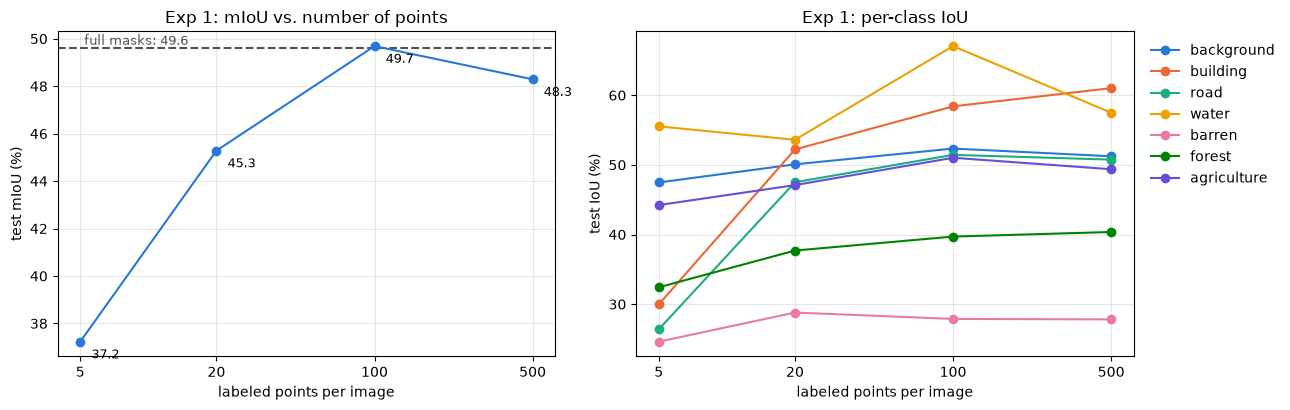

In [22]:
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]
pts = exp1[~np.isinf(exp1.index)]
pts_std = std.xs(EXP1_GAMMA, level="gamma").loc[pts.index]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
ax.errorbar(pts.index, pts["mIoU"], yerr=pts_std["mIoU"].fillna(0), marker="o", color=COLORS[0], capsize=3)
for n, v in pts["mIoU"].items():
    ax.annotate(f"{v:.1f}", (n, v), textcoords="offset points", xytext=(8, -12), fontsize=9)
if not np.isnan(dense_miou):
    ax.axhline(dense_miou, ls="--", color="#52514e", lw=1.5)
    ax.text(pts.index.min(), dense_miou, f" full masks: {dense_miou:.1f}", va="bottom", color="#52514e", fontsize=9)
ax.set_xscale("log"); ax.set_xticks(pts.index, [str(int(n)) for n in pts.index]); ax.minorticks_off()
ax.set_xlabel("labeled points per image"); ax.set_ylabel("test mIoU (%)"); ax.set_title("Exp 1: mIoU vs. number of points")
ax.grid(alpha=0.3)

ax = axes[1]
for c, col in zip(CLASSES, COLORS):
    ax.plot(pts.index, pts[c], marker="o", color=col, label=c)
ax.set_xscale("log"); ax.set_xticks(pts.index, [str(int(n)) for n in pts.index]); ax.minorticks_off()
ax.set_xlabel("labeled points per image"); ax.set_ylabel("test IoU (%)"); ax.set_title("Exp 1: per-class IoU")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUT / "figures" / "exp1.png", dpi=150)
plt.show()

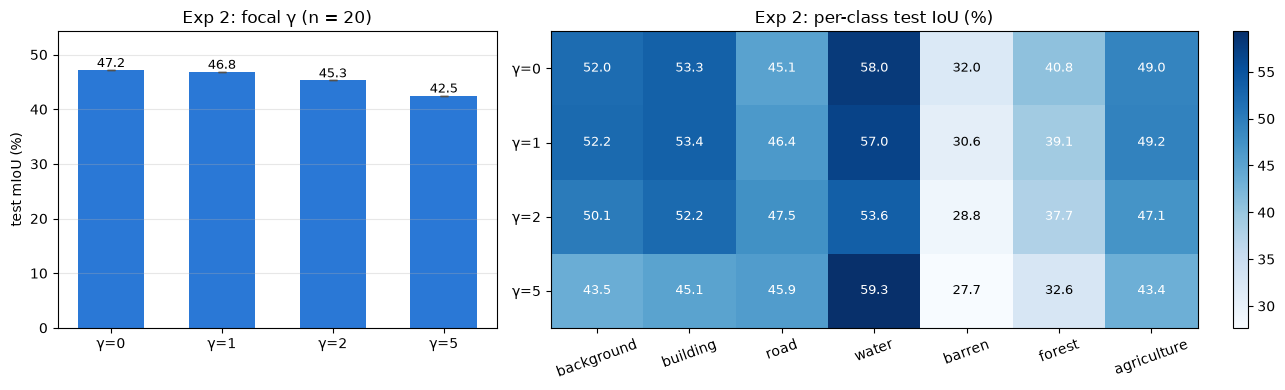

In [23]:
e2_std = std.xs(EXP2_N, level="n").loc[exp2.index]
fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw=dict(width_ratios=[1, 1.6]))
ax = axes[0]
err = e2_std["mIoU"].fillna(0).values
ax.bar(range(len(exp2)), exp2["mIoU"], yerr=err, color=COLORS[0], capsize=3, width=0.6,
       error_kw=dict(ecolor="#52514e", elinewidth=1.2))
for i, (v, e) in enumerate(zip(exp2["mIoU"], err)):
    ax.text(i, v + e, f"{v:.1f}", ha="center", va="bottom", fontsize=9)
ax.set_xticks(range(len(exp2)), [f"γ={g:g}" for g in exp2.index])
ax.set_ylabel("test mIoU (%)"); ax.set_title(f"Exp 2: focal γ (n = {EXP2_N})")
ax.set_ylim(0, (exp2["mIoU"] + err).max() * 1.15); ax.grid(axis="y", alpha=0.3)

ax = axes[1]
heat = exp2[CLASSES].values
im = ax.imshow(heat, cmap="Blues", aspect="auto")
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        ax.text(j, i, f"{heat[i, j]:.1f}", ha="center", va="center", fontsize=9,
                color="white" if heat[i, j] > 0.6 * np.nanmax(heat) else "black")
ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=20)
ax.set_yticks(range(len(exp2)), [f"γ={g:g}" for g in exp2.index])
ax.set_title("Exp 2: per-class test IoU (%)")
plt.colorbar(im, ax=ax, fraction=0.03)
plt.tight_layout()
plt.savefig(OUT / "figures" / "exp2.png", dpi=150)
plt.show()

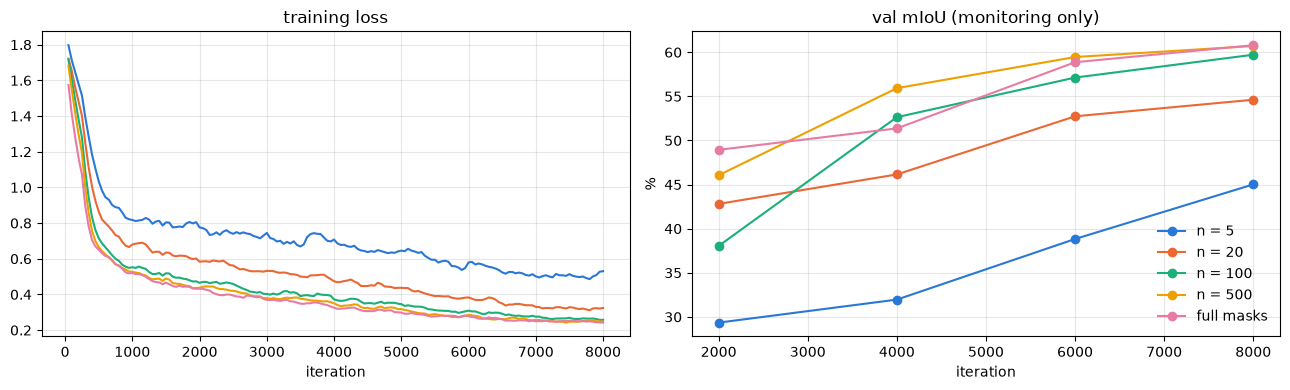

In [24]:
# training curves for the exp 1 runs (first seed)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for col, n in zip(COLORS, EXP1_N + [None]):
    f = OUT / "runs" / run_name(n, EXP1_GAMMA, SEEDS[0]) / "log.csv"
    if not f.exists():
        continue
    log = pd.read_csv(f)
    label = "full masks" if n is None else f"n = {n}"
    axes[0].plot(log["iter"], log["loss"].rolling(5, min_periods=1).mean(), color=col, label=label)
    v = log.dropna(subset=["val_mIoU"])
    axes[1].plot(v["iter"], 100 * v["val_mIoU"], marker="o", color=col, label=label)
axes[0].set_title("training loss"); axes[0].set_xlabel("iteration")
axes[1].set_title("val mIoU (monitoring only)"); axes[1].set_xlabel("iteration"); axes[1].set_ylabel("%")
axes[1].legend(frameon=False)
for a in axes:
    a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUT / "figures" / "training_curves.png", dpi=150)
plt.show()

### Qualitative results
Test images (2 urban, 2 rural), ground truth, and predictions of the exp 1 models.

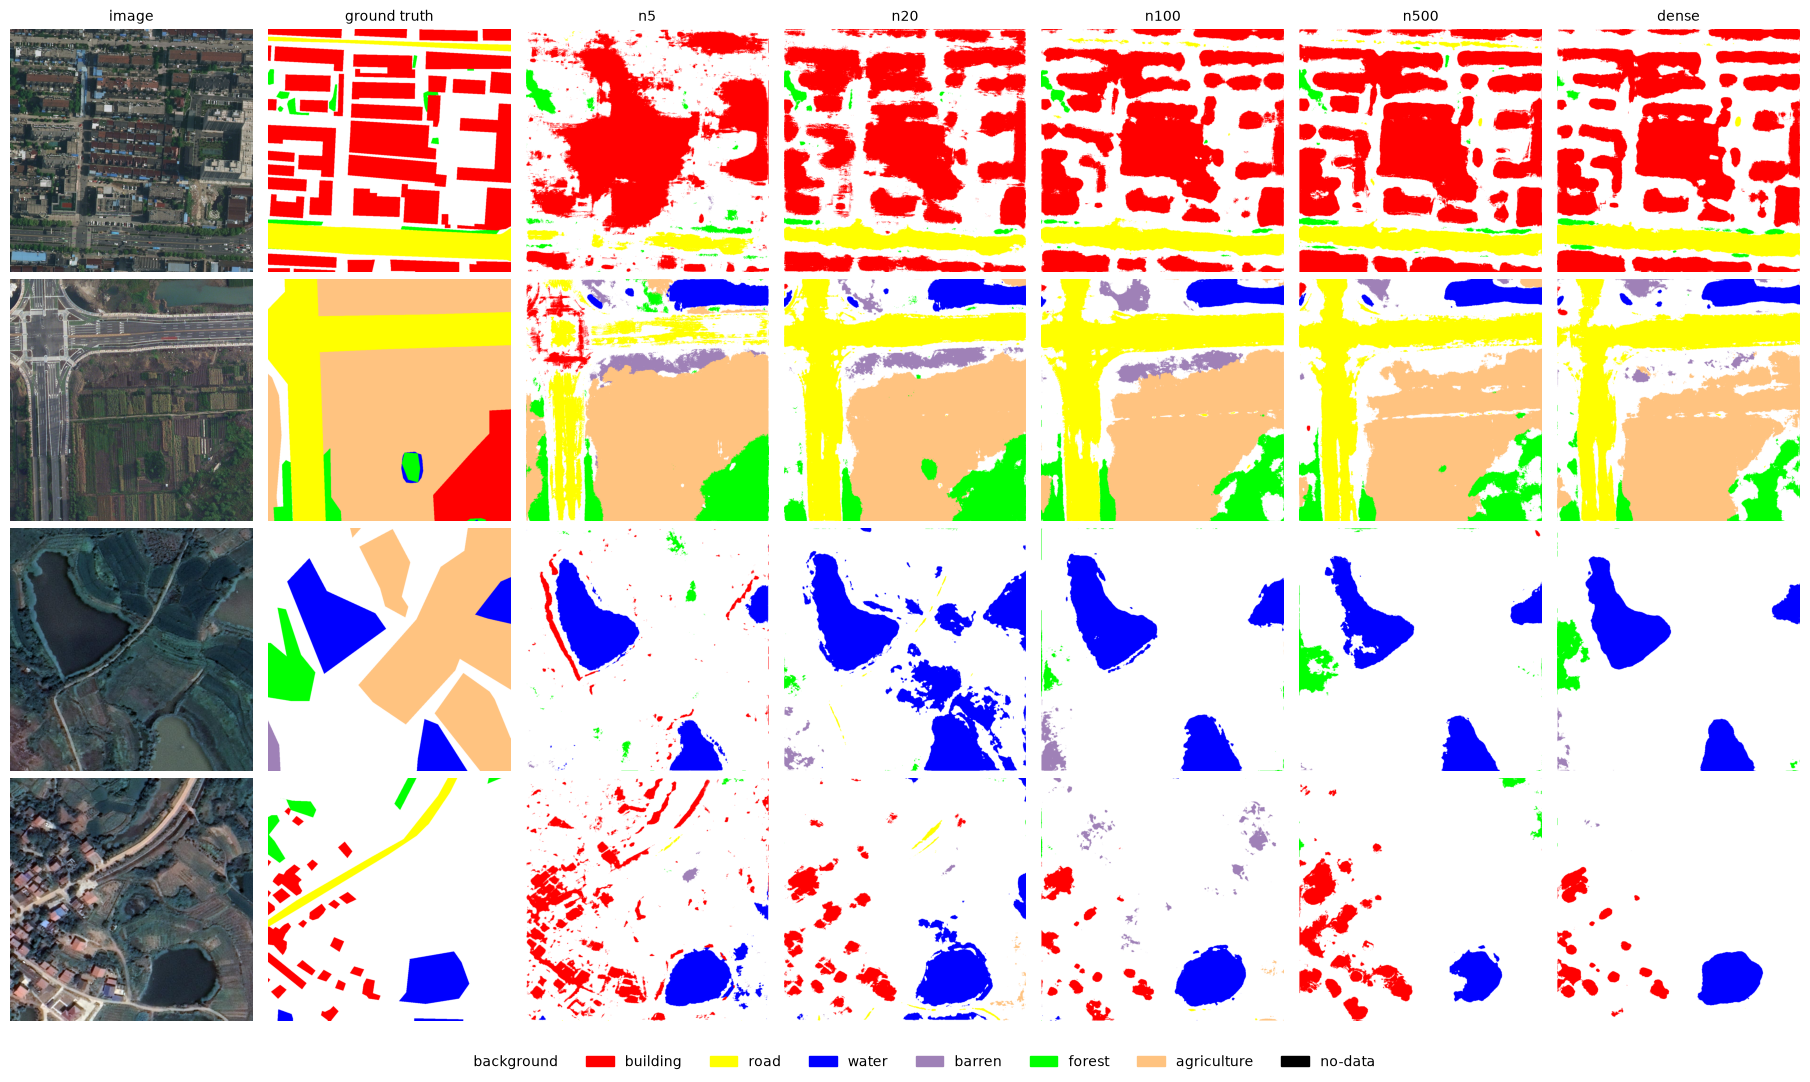

In [25]:
rng = np.random.default_rng(0)
show = [r for scene in ["Urban", "Rural"]
        for r in rng.choice([x for x in splits["test"] if x["scene"] == scene], 2, replace=False)]
show_runs = [run_name(n, EXP1_GAMMA, SEEDS[0]) for n in EXP1_N + [None]]
show_runs = [r for r in show_runs if (OUT / "runs" / r / "model.pt").exists()]

preds = {}
for name in show_runs:
    model = build_model(CFG, weights=None)
    model.load_state_dict(torch.load(OUT / "runs" / name / "model.pt", map_location="cpu"))
    model.to(device).eval()
    with torch.no_grad(), amp_ctx():
        preds[name] = [model(to_input(torch.from_numpy(read_img(r["image"]).transpose(2, 0, 1).copy())[None]))
                       .float().argmax(1)[0].cpu().numpy().astype(np.uint8) for r in show]
    del model

ncol = 2 + len(show_runs)
fig, axes = plt.subplots(len(show), ncol, figsize=(2.6 * ncol, 2.7 * len(show)))
for i, r in enumerate(show):
    gt = read_mask(r["mask"])
    axes[i, 0].imshow(read_img(r["image"]))
    axes[i, 1].imshow(colorize(gt))
    for j, name in enumerate(show_runs):
        p = preds[name][i].copy()
        p[gt == IGNORE] = IGNORE
        axes[i, 2 + j].imshow(colorize(p))
for j, t in enumerate(["image", "ground truth"] + [n.split("_")[0] for n in show_runs]):
    axes[0, j].set_title(t, fontsize=10)
for a in axes.ravel():
    a.axis("off")
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=PALETTE[k] / 255, label=c) for k, c in enumerate(CLASSES)] + [Patch(color="k", label="no-data")],
           loc="lower center", ncol=8, frameon=False)
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.savefig(OUT / "figures" / "qualitative.png", dpi=130)
plt.show()

## 7. Conclusions

All numbers are on the test set (official LoveDA Val), dense masks, full resolution, no TTA, one seed.

**Exp 1, annotation density (γ = 2)**
- 5 → 20 points: +8.1 mIoU, 20 → 100: +4.4, 100 → 500: −1.4. The last one is noise level (water IoU alone moves 9.5 between 100 and 500).
- 100 points per image (0.01% of pixels) gives 49.7 mIoU, the same as full masks (49.6). The hypothesis that a gap remains at 500 points is rejected.
- Hit hardest at 5 points: building (30.0 vs 60.1) and road (26.4 vs 51.2), and urban more than rural (−16.4 vs −8.5 mIoU). Barren stays around 25–30 IoU in every setting, full masks included.
- The plateau is most likely the domain gap: val (same areas as train) reaches ~60 mIoU at 100 / 500 / full masks, test ~50. Val curves were also still rising at 8k iterations.

**Exp 2, focal γ (n = 20)**
- γ = 0: 47.2, γ = 1: 46.8, γ = 2: 45.3, γ = 5: 42.5. The focal term did not help, so that hypothesis is rejected. γ = 5 hurts the common classes most (background −8.5, building −8.2 IoU vs γ = 0).
- With 20 points per image there is no mass of easy examples to down-weight, so the focal factor mostly removes signal. For point labels, plain partial CE (or γ ≤ 1) is the better choice.

**Caveats:** one seed; fixed 8k-iteration budget; the n500 run resumed from its 6k checkpoint after the crash above (data order after the resume differs from an uninterrupted run).

**Next:** seeds 1–2 (`SEEDS = [0, 1, 2]`), Exp 1 again with γ = 0, longer training; semi-supervised learning on the unlabeled pixels (pseudo-labels, consistency), histogram matching for the domain gap, flip TTA (`evaluate(..., tta=True)`), ensembles.